# 04 – Matrix Factorization

Phân rã ma trận rating thưa thành hai ma trận nhân tố ẩn (user × f) và (f × phim).

| Mô hình | Ghi chú |
|---|---|
| **BiasedMF / Funk SVD** | $\hat r_{ui}=\mu+b_u+b_i+p_u^\top q_i$, huấn luyện mini-batch Adam, điều chuẩn L2 |
| **Implicit ALS** | Hu–Koren–Volinsky: coi mọi rating là tương tác, tối ưu cho Top-N |

Số nhân tố của cả hai mô hình được chọn trên tập validation theo tiêu chí **NDCG@10**.

---
### Bản chất từng mô hình

**Họ mô hình: model-based CF, nhân tố ẩn (latent factors).** Giả định gu xem phim được quyết định bởi một số ít yếu tố ẩn $f$, ví dụ "hành động ↔ tâm lý" hay "phim cũ ↔ phim mới". Mỗi user là một vector $p_u \in \mathbb{R}^f$ (mức yêu thích từng yếu tố), mỗi phim là một vector $q_i \in \mathbb{R}^f$ (mức chứa từng yếu tố). Độ hợp nhau là $p_u^\top q_i$. Mô hình nén ma trận 6040 × 3706 về $(6040 + 3706) \times f$ tham số, nên **khái quát được** cả với cặp (user, phim) không có láng giềng chung, điều mà kNN không làm được.

**BiasedMF / Funk SVD:** học bằng tối ưu, chỉ trên ô đã chấm.
$$\hat r_{ui} = \mu + b_u + b_i + p_u^\top q_i, \qquad \min \sum_{(u,i)\,\text{đã chấm}} (r_{ui} - \hat r_{ui})^2 + \lambda\left(\|p_u\|^2 + \|q_i\|^2 + 0.1\,b_u^2 + 0.1\,b_i^2\right)$$
- Huấn luyện bằng mini-batch Adam (batch 8192).
- **Chỉ khớp những ô đã quan sát**, không giả định gì về ô trống. Đây là cách tiếp cận kinh điển cho bài toán dự đoán số sao (nền tảng của các đội dẫn đầu Netflix Prize).
- Hạn chế: không có tín hiệu nào phạt các phim user chưa xem, nên khi xếp hạng toàn bộ kho phim, các phim ít rating có điểm cao vẫn lọt lên đầu và NDCG thấp.

**Implicit ALS** (Hu, Koren & Volinsky 2008): đổi bài toán từ "đoán số sao" sang "đoán có tương tác hay không".
- Sở thích $p_{ui} = 1$ nếu user đã chấm phim (bất kể mấy sao), ngược lại bằng 0.
- Độ tin cậy $c_{ui} = 1 + \alpha$ với ô đã chấm, $c_{ui} = 1$ với ô trống.
$$\min \sum_{u,i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda\left(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\right)$$
- Hàm mục tiêu tính trên **mọi ô**, kể cả ô trống. Ô trống được xem là tín hiệu âm yếu ("có thể không thích, hoặc chưa biết đến").
- Cố định $Y$ thì bài toán theo $X$ là bình phương tối thiểu có nghiệm đóng, và ngược lại. ALS luân phiên giải hai bài toán này. Trên GPU, mọi user (hoặc mọi phim) được giải cùng lúc bằng một lệnh `solve` theo lô.
- Điểm $x_u^\top y_i$ là **mức ưa thích**, không phải số sao; chỉ dùng để xếp hạng.
- Mô hình học trực tiếp "user sẽ xem phim nào", nên NDCG và HitRate thuộc nhóm cao nhất trong dự án.

In [1]:
import sys, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))          # để import được package src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3})

from src.config import RESULTS_DIR
from src.experiment import SELECT_METRIC, load_experiment, make_validation, run_model, save_metrics, validate

exp = load_experiment()                # cùng dữ liệu + cùng phép chia + cùng seed cho mọi notebook
FIG = RESULTS_DIR / "figures"; FIG.mkdir(parents=True, exist_ok=True)
print(f"train={len(exp.train):,}  test={len(exp.test):,}  users={len(exp.user2idx):,}  items={len(exp.item2idx):,}")

train=800,193  test=200,016  users=6,040  items=3,706


In [2]:
from src.models.mf import BiasedMF, ImplicitALS
sub, val = make_validation(exp)

def sweep(make, values, label):
    out = []
    for v in values:
        m = make(v).fit(sub, exp.user2idx, exp.item2idx, exp.movies)
        out.append(dict(Model=label, factors=v, **validate(m, val)))
        print(label, v, round(out[-1][SELECT_METRIC], 4))
    return out

sw = pd.DataFrame(
    sweep(lambda f: BiasedMF(n_factors=f, epochs=15), (20, 50, 100, 200), "BiasedMF") +
    sweep(lambda f: ImplicitALS(n_factors=f, n_iter=10, alpha=20), (16, 32, 64, 128), "ImplicitALS"))
best = sw.loc[sw.groupby("Model")[SELECT_METRIC].idxmax()]; best

BiasedMF 20 0.0158


BiasedMF 50 0.0213


BiasedMF 100 0.0254


BiasedMF 200 0.0305


ImplicitALS 16 0.126


ImplicitALS 32 0.128


ImplicitALS 64 0.126


ImplicitALS 128 0.1236


,Model,factors,ValNDCG@10
3,BiasedMF,200,0.030538
5,ImplicitALS,32,0.127966


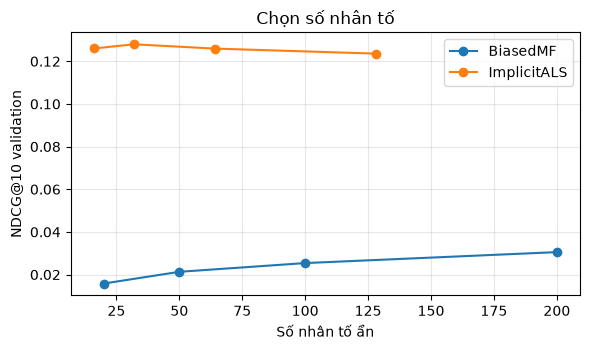

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, g in sw.groupby("Model"): ax.plot(g.factors, g[SELECT_METRIC], marker="o", label=name)
ax.set(xlabel="Số nhân tố ẩn", ylabel="NDCG@10 validation", title="Chọn số nhân tố"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "mf_factor_sweep.png"); plt.show()

## Huấn luyện lại trên toàn bộ train và đánh giá trên test

In [4]:
f = best.set_index("Model").factors.astype(int)
models = [BiasedMF(n_factors=f["BiasedMF"], epochs=15), ImplicitALS(n_factors=f["ImplicitALS"], n_iter=10, alpha=20)]
rows = []
for m in models:
    rows.append(run_model(m, exp)); print("done", m.name)
res = pd.DataFrame(rows)

done BiasedMF(f=200)


done ImplicitALS(f=32)


In [5]:
res[['Model', 'Precision@10', 'Recall@10', 'NDCG@10', 'HitRate@10', 'Coverage@20', 'FitTime_s']].round(4)

,Model,Precision@10,Recall@10,NDCG@10,HitRate@10,Coverage@20,FitTime_s
0,BiasedMF(f=200),0.0541,0.0314,0.0582,0.3441,0.4757,10.2931
1,ImplicitALS(f=32),0.2054,0.1690,0.2502,0.8220,0.5316,0.5827


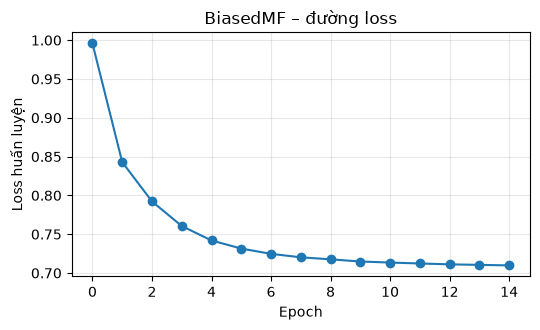

WindowsPath('D:/HỌC/kì 7/Machine Learning/machine_learning/outputs/metrics/mf.csv')

In [6]:
plt.figure(figsize=(5.5, 3.4)); plt.plot(models[0].history, marker="o")
plt.xlabel("Epoch"); plt.ylabel("Loss huấn luyện"); plt.title("BiasedMF – đường loss"); plt.tight_layout()
plt.savefig(FIG / "biasedmf_loss.png"); plt.show()
save_metrics(res.assign(Family="Matrix Factorization"), "mf")